# Random Forest Regression Evaluation — LLOY.L

**Project:** AI Quantitative Trading & Decision Intelligence System  
**Asset:** `LLOY.L` (Lloyds Banking Group, London Stock Exchange)  
**Evaluation status:** **Closed — not selected for further development**

## Objective

Document the existing Random Forest walk-forward validation results and the paired statistical comparisons against Ridge, LightGBM, and the established baselines.

This notebook is an analysis and documentation artifact. It **does not train models, rerun walk-forward evaluation, rerun statistical tests, use Final Test data, or perform backtesting**. It reads the previously generated CSV artifacts only.


## 1. Evaluation scope and protocol

- **Market-data source:** Yahoo Finance (`yfinance`).
- **Validation period:** 23 October 2023 to 22 October 2025.
- **Latest permitted input session:** 22 October 2025.
- **Forecast horizons:** 1, 5, and 10 trading sessions.
- **Validation approach:** weekly expanding-window walk-forward validation, with mature labels only and a minimum of 500 eligible training samples.
- **Reference models:** Ridge regression and LightGBM regression.
- **Baselines:** zero return, historical mean, and historical median.
- **Multiple-comparison control:** Holm correction across the 45 paired comparisons.
- **HAC/Newey–West lags:** 0, 4, and 9 for horizons 1, 5, and 10, respectively.
- **Moving-block bootstrap:** 5,000 repetitions per comparison, with block lengths 1, 5, and 10 sessions, respectively.
- **Final Test:** excluded from model selection and validation.
- **Trading backtest:** not performed.

Forecast accuracy and directional correctness are predictive metrics; neither establishes trading profitability after transaction costs, slippage, or risk constraints.


## 2. Load the existing evaluation artifacts

Run this notebook from the repository root or from within the `notebooks/` directory. The code searches the expected repository-relative locations and fails clearly if a required artifact is missing.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (root for root in CANDIDATE_ROOTS if (root / "reports").is_dir()),
    Path.cwd(),
)

RF_DIR = PROJECT_ROOT / "reports/model_evaluation/LLOY.L/random_forest_regression"
RIDGE_DIR = PROJECT_ROOT / "reports/model_evaluation/LLOY.L/ridge_regression"
LIGHTGBM_DIR = PROJECT_ROOT / "reports/model_evaluation/LLOY.L/lightgbm_regression"

RF_METRICS_PATH = RF_DIR / "random_forest_validation_metrics.csv"
RF_STATS_PATH = RF_DIR / "random_forest_paired_statistical_tests.csv"
RF_ALIGNED_PATH = RF_DIR / "random_forest_all_models_aligned_predictions.csv"
RIDGE_METRICS_PATH = RIDGE_DIR / "ridge_validation_metrics.csv"
LIGHTGBM_METRICS_PATH = LIGHTGBM_DIR / "lightgbm_validation_metrics.csv"

required_paths = [RF_METRICS_PATH, RF_STATS_PATH, RF_ALIGNED_PATH]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    missing = "\n".join(f"- {path}" for path in missing_paths)
    raise FileNotFoundError(
        "Required Random Forest evaluation artifacts were not found. "
        "Run this notebook from the repository root or notebooks/ directory.\n"
        f"Missing files:\n{missing}"
    )

rf_metrics = pd.read_csv(RF_METRICS_PATH)
paired_tests = pd.read_csv(RF_STATS_PATH)
aligned_predictions = pd.read_csv(RF_ALIGNED_PATH)

print(f"Project root: {PROJECT_ROOT}")
print(f"Aligned prediction records: {len(aligned_predictions):,}")
print(f"Paired statistical comparisons: {len(paired_tests):,}")
print("Final Test data used: False")
print("Backtesting performed: False")

display(rf_metrics)


Project root: /home/anderjcruz/projects/Quantitative-Trading
Aligned prediction records: 9,030
Paired statistical comparisons: 45
Final Test data used: False
Backtesting performed: False


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,random_forest_regression,506,0.009811,0.013737,0.500000,-0.015053,-0.018076
1,5,random_forest_regression,502,0.025720,0.035130,0.549801,0.157526,0.002980
2,10,random_forest_regression,497,0.038920,0.050940,0.498994,-0.001620,-0.043407


## 3. Random Forest validation performance

The following metrics are read from the saved walk-forward validation report. Negative out-of-sample R² values indicate that the model did not outperform the zero-variance benchmark under that metric. Small differences in individual metrics should not be treated as evidence of model superiority without the paired statistical analysis below.


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,random_forest_regression,506,0.009811,0.013737,0.500000,-0.015053,-0.018076
1,5,random_forest_regression,502,0.025720,0.035130,0.549801,0.157526,0.002980
2,10,random_forest_regression,497,0.038920,0.050940,0.498994,-0.001620,-0.043407


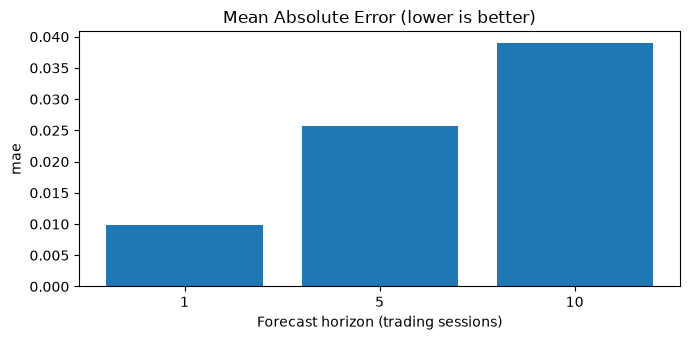

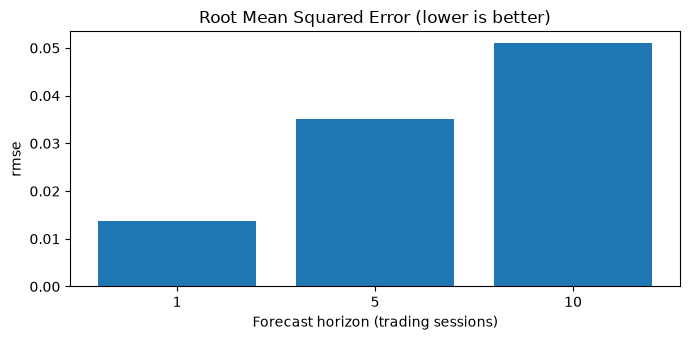

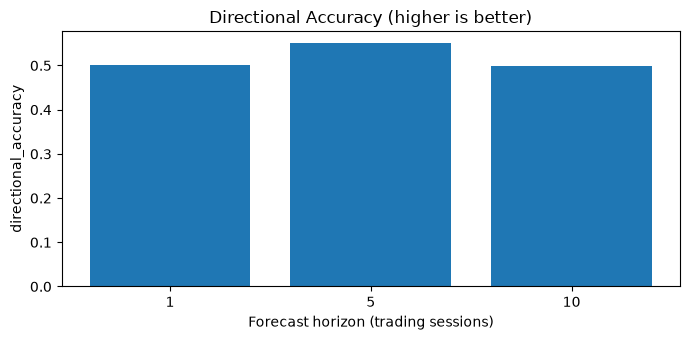

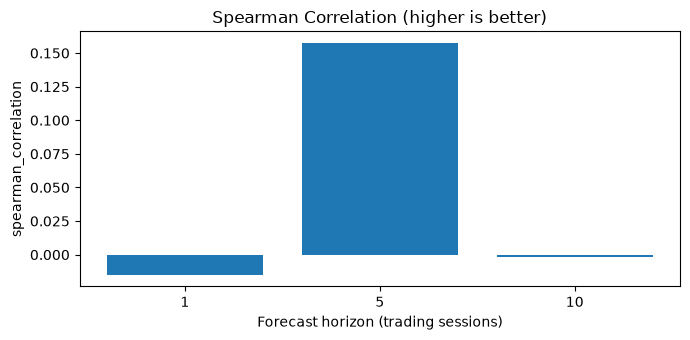

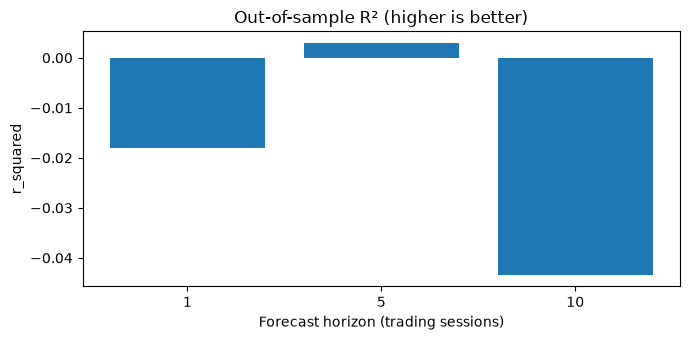

In [2]:
metric_columns = [
    column for column in [
        "horizon", "model", "sample_size", "mae", "rmse",
        "directional_accuracy", "spearman_correlation", "r_squared"
    ]
    if column in rf_metrics.columns
]
display(rf_metrics[metric_columns].sort_values("horizon"))

plot_metrics = [
    ("mae", "Mean Absolute Error (lower is better)"),
    ("rmse", "Root Mean Squared Error (lower is better)"),
    ("directional_accuracy", "Directional Accuracy (higher is better)"),
    ("spearman_correlation", "Spearman Correlation (higher is better)"),
    ("r_squared", "Out-of-sample R² (higher is better)"),
]

for column, title in plot_metrics:
    if column not in rf_metrics.columns:
        continue
    plot_data = rf_metrics.sort_values("horizon")
    plt.figure(figsize=(7, 3.5))
    plt.bar(plot_data["horizon"].astype(str), plot_data[column])
    plt.title(title)
    plt.xlabel("Forecast horizon (trading sessions)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()


## 4. Comparison with Ridge and LightGBM

This section loads the already saved Ridge and LightGBM metric files when present. If either expected file is unavailable, the notebook reports that fact rather than silently substituting another artifact.


In [3]:
comparison_frames = [rf_metrics.assign(model="random_forest_regression")]

for model_name, path in [
    ("ridge_regression", RIDGE_METRICS_PATH),
    ("lightgbm_regression", LIGHTGBM_METRICS_PATH),
]:
    if path.exists():
        frame = pd.read_csv(path)
        frame["model"] = model_name
        comparison_frames.append(frame)
    else:
        print(f"Not found; omitted from descriptive metric table: {path}")

model_comparison = pd.concat(comparison_frames, ignore_index=True, sort=False)
available_columns = [
    column for column in [
        "horizon", "model", "sample_size", "mae", "rmse",
        "directional_accuracy", "spearman_correlation", "r_squared"
    ]
    if column in model_comparison.columns
]
display(
    model_comparison[available_columns]
    .sort_values(["horizon", "model"])
    .reset_index(drop=True)
)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,lightgbm_regression,506,0.009854,0.013752,0.535573,0.105869,-0.020374
1,1,random_forest_regression,506,0.009811,0.013737,0.500000,-0.015053,-0.018076
2,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919
3,5,lightgbm_regression,502,0.026133,0.035502,0.549801,0.158544,-0.018253
4,5,random_forest_regression,502,0.025720,0.035130,0.549801,0.157526,0.002980
5,5,ridge_regression,502,0.026023,0.035465,0.597610,0.178884,-0.016138
6,10,lightgbm_regression,497,0.039940,0.052301,0.492958,0.075672,-0.099903
7,10,random_forest_regression,497,0.038920,0.050940,0.498994,-0.001620,-0.043407
8,10,ridge_regression,497,0.039124,0.051289,0.561368,0.123284,-0.057729


## 5. Paired statistical comparisons

The statistical report compares Random Forest against five references for each horizon and three paired outcomes: absolute error, squared error, and directional correctness. Holm-adjusted p-values control the family-wise error rate across the full set of 45 comparisons.

For error differences, **negative values favour Random Forest**. For directional-correctness differences, **positive values favour Random Forest**.


In [4]:
expected_columns = [
    "horizon", "metric", "model_b", "sample_size", "mean_difference",
    "hac_p_value", "holm_adjusted_p_value",
    "bootstrap_ci_95_lower", "bootstrap_ci_95_upper",
    "significant_after_holm_5pct",
]
available_stats_columns = [
    column for column in expected_columns if column in paired_tests.columns
]
display(
    paired_tests[available_stats_columns]
    .sort_values(["horizon", "metric", "model_b"])
    .reset_index(drop=True)
)

significant = paired_tests[
    paired_tests["significant_after_holm_5pct"].astype(str).str.lower().isin(["true", "1"])
].copy()

print(f"Significant comparisons after Holm correction: {len(significant)}")
display(significant[available_stats_columns])


,horizon,metric,model_b,sample_size,mean_difference,hac_p_value,holm_adjusted_p_value,bootstrap_ci_95_lower,bootstrap_ci_95_upper,significant_after_holm_5pct
0,1,absolute_error,historical_mean,506,5.201163e-05,2.959988e-01,1.000000e+00,-0.000045,0.000150,False
1,1,absolute_error,historical_median,506,1.775964e-05,7.212085e-01,1.000000e+00,-0.000078,0.000113,False
2,1,absolute_error,lightgbm_regression,506,-4.308788e-05,6.166067e-01,1.000000e+00,-0.000211,0.000123,False
3,1,absolute_error,ridge_regression,506,3.400162e-05,5.167446e-01,1.000000e+00,-0.000067,0.000139,False
4,1,absolute_error,zero_return,506,5.393663e-05,2.757152e-01,1.000000e+00,-0.000042,0.000151,False
5,1,directional_correctness,historical_mean,506,-5.928854e-03,8.694136e-01,1.000000e+00,-0.073123,0.067194,False
6,1,directional_correctness,historical_median,506,2.964427e-02,1.149606e-01,1.000000e+00,-0.005929,0.067194,False
7,1,directional_correctness,lightgbm_regression,506,-3.754941e-02,8.832837e-02,1.000000e+00,-0.081028,0.003953,False
8,1,directional_correctness,ridge_regression,506,-7.905138e-03,7.518059e-01,1.000000e+00,-0.057312,0.039526,False
9,1,directional_correctness,zero_return,506,4.841897e-01,3.764666e-99,1.694100e-97,0.438735,0.527668,True


Significant comparisons after Holm correction: 4


,horizon,metric,model_b,sample_size,mean_difference,hac_p_value,holm_adjusted_p_value,bootstrap_ci_95_lower,bootstrap_ci_95_upper,significant_after_holm_5pct
8,1,directional_correctness,zero_return,506,0.484190,3.764666e-99,1.694100e-97,0.438735,0.527668,True
23,5,directional_correctness,zero_return,502,0.539841,2.695998e-58,1.186239e-56,0.474104,0.605578,True
29,5,directional_correctness,historical_median,502,0.173307,3.955430e-05,1.661281e-03,0.091633,0.254980,True
38,10,directional_correctness,zero_return,497,0.488934,3.479222e-44,1.496065e-42,0.420523,0.555382,True


## 6. Findings

### 6.1 Random Forest versus the established machine-learning models

Across horizons 1, 5, and 10, **none of the nine comparisons against Ridge and LightGBM was statistically significant after Holm correction** (three metrics for each of two reference models at each horizon). The confidence intervals for these comparisons include zero.

Most corresponding bootstrap confidence intervals include zero. One exception is the 10-session squared-error comparison against LightGBM, whose reported bootstrap interval excludes zero even though its Holm-adjusted HAC p-value is not significant. This difference between inferential summaries should be retained as a limitation rather than treated as proof of superiority. Overall, the Random Forest has not demonstrated robust predictive superiority over the existing machine-learning models on this validation period.

### 6.2 Baseline comparisons

The saved report contains statistically significant directional-correctness differences against the zero-return baseline at all three horizons, and against the historical-median baseline at the 5-session horizon. These results are metric-specific and do not establish overall forecast superiority or economic value. In particular, the directional-correctness result against a zero-return reference must be interpreted in the context of how that baseline's directional prediction is defined.

### 6.3 Descriptive performance

The Random Forest's validation metrics are mixed across horizons. The 5-session horizon has a slightly positive out-of-sample R² (approximately 0.003), while horizons 1 and 10 have negative out-of-sample R². This is not enough to justify further tuning given the absence of statistically significant improvements over Ridge or LightGBM.


## 7. Limitations

- Conclusions apply to `LLOY.L`, the stated validation period, the recorded feature set, and the evaluated Random Forest configuration.
- The analysis does not establish that the model would generalise to other equities, markets, or periods.
- Statistical significance in a predictive metric is not equivalent to a profitable trading strategy.
- No trading backtest, transaction-cost analysis, slippage model, portfolio construction, or risk-adjusted performance evaluation was conducted.
- The Final Test period remains excluded from model selection and this evaluation.
- This notebook reports existing artifacts; it does not independently recompute the statistical tests.


## 8. Decision and closure

**Decision: close the Random Forest evaluation and do not advance this configuration.**

Rationale:

1. No statistically significant improvement over Ridge or LightGBM remained after Holm correction.
2. Predictive performance was mixed across the three forecast horizons.
3. The isolated baseline-comparison findings do not demonstrate overall predictive superiority or trading profitability.
4. Further Random Forest hyperparameter tuning is not justified at this stage.

**Status:** Random Forest evaluation complete; no further tuning authorised in this phase. Preserve the generated predictions, metrics, aligned comparison dataset, and statistical report for auditability. No model training, Final Test evaluation, or backtesting was performed in this notebook.
